# **Môi Trường Thực THi**

In [1]:
import os
import random
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)

import numpy as np
np.random.seed(SEED)

import tensorflow as tf
tf.random.set_seed(SEED)

import warnings
warnings.filterwarnings('ignore')

print("SEED =", SEED)
print("TensorFlow version:", tf.__version__)

SEED = 42
TensorFlow version: 2.19.0


# **Thư Viện Và Tiện Ích**

In [2]:
import pickle
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from datetime import datetime
import re, unicodedata
from collections import defaultdict
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Thiết lập kích thước mặc định cho tất cả các biểu đồ (chiều rộng 12, chiều cao 5)
plt.rcParams['figure.figsize'] = (12,5)
# Áp dụng phong cách hiển thị biểu đồ 'whitegrid' từ Seaborn
sns.set(style='whitegrid')

# **Upload Data**

In [3]:
DU_LIEU_FILE = '/content/ThoiTiet.csv'
TRAM_FILE = '/content/Tram.csv'
SUKIEN_FILE = '/content/ThienTai.csv'
print("Files:", DU_LIEU_FILE, TRAM_FILE, SUKIEN_FILE)
for f in [DU_LIEU_FILE, TRAM_FILE, SUKIEN_FILE]:
    if not os.path.exists(f):
        print(f"WARNING: file not found: {f}")
# Đọc file (giả định encoding UTF-8 hoặc có BOM)
du_lieu = pd.read_csv(DU_LIEU_FILE)
tram = pd.read_csv(TRAM_FILE)
sukien = pd.read_csv(SUKIEN_FILE)
print("Loaded shapes:", du_lieu.shape, tram.shape, sukien.shape)
# Hiển thị một số dòng đầu tiên để kiểm tra dữ liệu
print("== DuLieu_ThoiTiet sample ==")
display(du_lieu.head())
print("== Tram_QuanTrac sample ==")
display(tram.head())
print("== SuKien_ThienTai sample ==")
display(sukien.head())

Files: /content/ThoiTiet.csv /content/Tram.csv /content/ThienTai.csv
Loaded shapes: (345158, 16) (25, 9) (200, 6)
== DuLieu_ThoiTiet sample ==


,ID,Ngay,Thang,Nam,Ngay_Thang_Nam,NhietDo_TrungBinh,NhietDo_ThapNhat,NhietDo_CaoNhat,LuongMua_mm,DoAm_%,TocDoGio,HuongGio_Toado,SoGioNang,ApSuat_kPa,DiemSuong,Mua
0,1.0,1.0,1.0,2010.0,1/1/2010,16.84,13.73,20.44,5.23,91.14,2.14,78.3,3.03,100.48,15.33,Đông
1,1.0,2.0,1.0,2010.0,2/1/2010,17.56,14.30,21.29,0.69,90.35,1.94,52.4,4.26,100.51,15.90,Đông
2,1.0,3.0,1.0,2010.0,3/1/2010,16.84,13.54,21.41,0.09,87.79,2.05,93.3,8.82,100.58,14.71,Đông
3,1.0,4.0,1.0,2010.0,4/1/2010,19.25,14.23,25.60,0.01,87.63,2.17,148.3,8.18,100.10,17.07,Đông
4,1.0,5.0,1.0,2010.0,5/1/2010,21.89,17.17,28.63,0.06,84.74,2.21,150.4,12.63,100.02,19.10,Đông


== Tram_QuanTrac sample ==


,ID,Ten_Tram,Ten_Tinh,Vi_do,Kinh_do,Do_cao_m,Dia_hinh,Vung_Mien,Dien_tich_km2
0,1,Hà Nội,Hà Nội,21.03,105.85,10,Đồng bằng,Tây Bắc,3345.0
1,2,Hà Giang,Hà Giang,22.83,104.98,1200,Núi cao,Đông Bắc,7915.0
2,4,Cao Bằng,Cao Bằng,22.67,106.26,200,Đồi thấp,Đông Bắc,6700.0
3,6,Bắc Kạn,Bắc Kạn,22.14,105.83,600,Núi trung bình,Đông Bắc,4859.0
4,8,Tuyên Quang,Tuyên Quang,21.82,105.22,1000,Núi cao,Đông Bắc,5867.0


== SuKien_ThienTai sample ==


,Ten_Tinh,Nam,Loai_ThienTai,Muc_Do_TacDong,SoNgay_MuaLon,SoCon_Bao
0,Bắc Giang,2010,Bão,Rất mạnh,1,1
1,Bắc Giang,2011,Bão,Rất mạnh,1,1
2,Bắc Giang,2012,Bão,Rất mạnh,3,2
3,Bắc Giang,2013,Bão,Rất mạnh,3,2
4,Bắc Giang,2014,Bão,Rất mạnh,1,1


# **Đồng Bộ Dữ liệu Ngày**

In [4]:
def clean_cols(df):
    df = df.copy()
    df.columns = [c.strip().replace(' ', '_') for c in df.columns]
    return df

du_lieu = clean_cols(du_lieu)
tram = clean_cols(tram)
sukien = clean_cols(sukien)

# Chuẩn hóa cột ngày cho du_lieu
if 'Ngay_Thang_Nam' in du_lieu.columns:
    du_lieu['Date'] = pd.to_datetime(du_lieu['Ngay_Thang_Nam'], errors='coerce', dayfirst=True)
else:
    if all(col in du_lieu.columns for col in ['Nam', 'Thang', 'Ngay']):
        du_lieu['Date'] = pd.to_datetime(dict(year=du_lieu['Nam'], month=du_lieu['Thang'], day=du_lieu['Ngay']))
    else:
        # Thử đoán cột ngày khác (ví dụ 'Date')
        if 'Date' in du_lieu.columns:
            du_lieu['Date'] = pd.to_datetime(du_lieu['Date'], errors='coerce')
        else:
            raise ValueError("Không tìm thấy cột ngày hợp lệ trong DuLieu_ThoiTiet.csv")

# Đảm bảo cột ID tồn tại để merge
if 'ID' not in tram.columns:
    raise ValueError("Tram.csv cần cột 'ID'")
if 'ID' not in du_lieu.columns:
    raise ValueError("DuLieu phải có cột 'ID' để merge với Tram.csv")

# Tìm cột Ten_Tinh trong sukien
if 'Ten_Tinh' not in sukien.columns:
    possible = [c for c in sukien.columns if 'tinh' in c.lower()]
    if len(possible) > 0:
        sukien = sukien.rename(columns={possible[0]: 'Ten_Tinh'})
    else:
        print("WARNING: Không tìm thấy 'Ten_Tinh' trong SuKien; merge theo năm sẽ vẫn thực hiện nếu có 'Nam'.")

# Chuẩn hóa cột Nam
if 'Nam' not in du_lieu.columns and 'Year' in du_lieu.columns:
    du_lieu = du_lieu.rename(columns={'Year':'Nam'})
if 'Nam' not in sukien.columns and 'Year' in sukien.columns:
    sukien = sukien.rename(columns={'Year':'Nam'})

# Merge
df = du_lieu.merge(tram, on='ID', how='left', suffixes=('','_tram'))
if 'Nam' in df.columns and 'Ten_Tinh' in sukien.columns and 'Nam' in sukien.columns:
    df = df.merge(sukien, on=['Ten_Tinh','Nam'], how='left', suffixes=('','_sk'))
else:
    # Nếu không có Ten_Tinh, thử merge theo Nam nếu có
    if 'Nam' in df.columns and 'Nam' in sukien.columns:
        df = df.merge(sukien, on=['Nam'], how='left', suffixes=('','_sk'))

print("Merged df shape:", df.shape)

Merged df shape: (345158, 29)


# **Gán Giá Trị Tham Số**

***Xác Định Biến Mục Tiêu***

In [5]:
# Danh sách biến mục tiêu mong muốn (tên biến nội bộ dùng cho ánh xạ)
TARGETS = [
    'Nhiet_do', 'Luong_Mua_mm', 'Do_Am', 'Toc_Do_Gio',
    'HuongGio_Toado', 'So_Gio_Nang', 'Ap_Suat_kPa', 'Diem_Suong'
]

# In ra vài cột đầu để người dùng kiểm tra nhanh (tối đa 40)
print("Các cột hiện có trong dữ liệu (tối đa 40):")
print(df.columns.tolist()[:40])

Các cột hiện có trong dữ liệu (tối đa 40):
['ID', 'Ngay', 'Thang', 'Nam', 'Ngay_Thang_Nam', 'NhietDo_TrungBinh', 'NhietDo_ThapNhat', 'NhietDo_CaoNhat', 'LuongMua_mm', 'DoAm_%', 'TocDoGio', 'HuongGio_Toado', 'SoGioNang', 'ApSuat_kPa', 'DiemSuong', 'Mua', 'Date', 'Ten_Tram', 'Ten_Tinh', 'Vi_do', 'Kinh_do', 'Do_cao_m', 'Dia_hinh', 'Vung_Mien', 'Dien_tich_km2', 'Loai_ThienTai', 'Muc_Do_TacDong', 'SoNgay_MuaLon', 'SoCon_Bao']


***Lựa Chọn Cột Tối Ưu***

In [6]:
# Hàm chuẩn hóa tên: xóa dấu, chuyển thường, chỉ giữ chữ/số/_
def normalize_text(s):
    """Chuẩn hóa: xóa dấu, chữ thường, chỉ giữ ký tự chữ/số/_."""
    if s is None: return ''
    s = str(s).strip().lower()                             # strip + lower
    s = unicodedata.normalize('NFKD', s)                   # tách ký tự unicode
    s = ''.join([c for c in s if not unicodedata.combining(c)])  # bỏ dấu
    s = re.sub(r'[^0-9a-z_]', '', s)                       # chỉ giữ [0-9a-z_]
    return s

# Hàm tách token: giữ chữ và số, thay ký tự không hợp lệ bằng khoảng trắng, trả về tập token
def token_set(s):
    """Tách chuỗi thành tập token (dựa vào chữ & số)."""
    s2 = unicodedata.normalize('NFKD', str(s).lower())     # chuẩn hóa unicode + lower
    s2 = re.sub(r'[^0-9a-z ]', ' ', s2)                    # thay ký tự lạ bằng space
    return set(t for t in s2.split() if t.strip())         # trả về tập token không rỗng

# Lấy danh sách cột từ DataFrame
cols = list(df.columns)
# Tạo dict ánh xạ: cột gốc -> tên chuẩn hóa
norm_cols = {c: normalize_text(c) for c in cols}
# Tạo dict ánh xạ: cột gốc -> tập token (dùng để so khớp bằng token)
token_cols = {c: token_set(c) for c in cols}
# Từ khoá (hand-crafted) cho từng biến mục tiêu — dùng để so khớp với tên cột
keywords = {
    'Nhiet_do': ['temp','nhiet','nhiệt','temperature'],
    'Luong_Mua_mm': ['rain','mua','precip','luongmua','mm'],
    'Do_Am': ['humid','doam','độẩm','ẩm','humidity'],
    'Toc_Do_Gio': ['wind','tocdo','tốcđộ','speed','wind_speed'],
    'HuongGio_Toado': ['huong','direction','winddir','wind_dir','toado','coord','vector','azimuth'],
    'So_Gio_Nang': ['sun','sogionang','so_gio','sunhour','sun_hours'],
    'Ap_Suat_kPa': ['ap','pressure','ap_suat','kpa','hpa'],
    'Diem_Suong': ['dew','diem_suong','dewpoint','sương']
}
# Chuẩn hóa các từ khoá bằng hàm normalize_text để so sánh nhất quán
kw_norm = {k: [normalize_text(w) for w in v] for k,v in keywords.items()}

***Tính Điểm Khớp Và Chọn Cột Tốt Nhất***

In [7]:
# scores sẽ giữ danh sách (cột, điểm, lý do) cho từng target
scores = defaultdict(list)
# Với mỗi biến mục tiêu, so khớp từng cột và tính điểm dựa trên các mức độ tương đồng
for tgt in TARGETS:
    for c in cols:
        ncol = norm_cols[c]            # tên cột đã chuẩn hóa
        tcol_tokens = token_cols[c]    # tập token của cột
        score, reasons = 0, []         # điểm và danh sách nguyên nhân (lý do)
        for kw in kw_norm[tgt]:
            # ưu tiên khớp chính xác
            if ncol == kw:
                score += 50; reasons.append(f'exact({kw})')
            # khớp cạnh (bắt đầu/ kết thúc)
            elif ncol.startswith(kw) or ncol.endswith(kw):
                score += 20; reasons.append(f'edge({kw})')
            # khớp là substring
            elif kw in ncol:
                score += 5; reasons.append(f'sub({kw})')
            # khớp theo token (tách theo spaces/những ký tự không phải chữ số/chữ)
            if kw in tcol_tokens:
                score += 10; reasons.append(f'token({kw})')
        # chỉ lưu cột nếu có điểm > 0 (có ít nhất 1 match)
        if score > 0:
            scores[tgt].append((c, score, ','.join(reasons)))
# Chọn ánh xạ tốt nhất cho mỗi target, tránh dùng cùng 1 cột cho nhiều target
best_mapping, used = {}, set()
for tgt, lst in scores.items():
    # sắp xếp giảm dần theo điểm
    lst = sorted(lst, key=lambda x: x[1], reverse=True)
    for col, sc, rs in lst:
        if col not in used:               # dùng cột chưa bị chiếm
            best_mapping[tgt] = {'col': col, 'score': sc, 'reason': rs}
            used.add(col)
            break                          # dừng sau khi chọn 1 cột cho target
final_mapping = {t: best_mapping[t]['col'] if t in best_mapping else None for t in TARGETS}
keep_cols = [c for c in set([v for v in final_mapping.values() if v] + ['Date','ID','Ten_Tinh','Nam']) if c in df.columns]

df2 = df[keep_cols].copy()
rename_map = {final_mapping[t]: t for t in TARGETS if final_mapping.get(t)}
df2.rename(columns=rename_map, inplace=True)
print("df2 columns:", df2.columns.tolist())

missing = [t for t, v in final_mapping.items() if v is None]
if missing:
    print("Các biến chưa tìm thấy cột tương ứng:", missing)

df2 columns: ['ID', 'Nhiet_do', 'Luong_Mua_mm', 'Diem_Suong', 'Nam', 'HuongGio_Toado', 'Do_Am', 'Toc_Do_Gio', 'So_Gio_Nang', 'Date', 'Ten_Tinh', 'Ap_Suat_kPa']


# **Xây Dựng Khung Dữ Liệu Chuẩn Hóa**

In [8]:
# Nếu một số target chưa có, vẫn tiếp tục với những biến có sẵn
features = [c for c in TARGETS if c in df2.columns]
if len(features) == 0:
    raise ValueError("Không tìm thấy bất kỳ biến mục tiêu nào trong df2. Kiểm tra mapping.")
print("Features used:", features)

Features used: ['Nhiet_do', 'Luong_Mua_mm', 'Do_Am', 'Toc_Do_Gio', 'HuongGio_Toado', 'So_Gio_Nang', 'Ap_Suat_kPa', 'Diem_Suong']


# **Tạo Chuỗi Thời Gian Cho Từng Trạm**

***Lấy List Các Trạm Tồn Tại***

In [9]:
stations = df2['ID'].unique()             # Lấy tất cả danh sách ID trạm duy nhất
print("Số trạm có trong dữ liệu:", len(stations))

Số trạm có trong dữ liệu: 26


***Sử Dụng ID Demo***

In [10]:
# Chọn 1 trạm để demo (trạm đầu tiên trong danh sách)
station_id = stations[0]
print("Sử dụng trạm ID để demo =", station_id)
# Lọc dữ liệu theo trạm và sắp xếp theo ngày
df_station = df2[df2['ID'] == station_id].sort_values('Date').set_index('Date')
# Xử lý dữ liệu trống: nội suy theo thời gian + ffill + bfill
df_station = df_station.interpolate(method='time').ffill().bfill()
# Xem 10 dòng đầu tiên sau tiền xử lý
print("df_station shape:", df_station.shape)
display(df_station.head(10))

Sử dụng trạm ID để demo = 1.0
df_station shape: (5479, 11)


,ID,Nhiet_do,Luong_Mua_mm,Diem_Suong,Nam,HuongGio_Toado,Do_Am,Toc_Do_Gio,So_Gio_Nang,Ten_Tinh,Ap_Suat_kPa
Date,,,,,,,,,,,
2010-01-01,1.0,16.84,5.23,15.33,2010.0,78.3,91.14,2.14,3.03,Hà Nội,100.48
2010-01-02,1.0,17.56,0.69,15.90,2010.0,52.4,90.35,1.94,4.26,Hà Nội,100.51
2010-01-03,1.0,16.84,0.09,14.71,2010.0,93.3,87.79,2.05,8.82,Hà Nội,100.58
2010-01-04,1.0,19.25,0.01,17.07,2010.0,148.3,87.63,2.17,8.18,Hà Nội,100.10
2010-01-05,1.0,21.89,0.06,19.10,2010.0,150.4,84.74,2.21,12.63,Hà Nội,100.02
2010-01-06,1.0,15.85,4.48,12.11,2010.0,60.7,79.56,3.6,6.93,Hà Nội,100.71
2010-01-07,1.0,14.40,1.51,11.95,2010.0,59.7,85.69,2.33,4.14,Hà Nội,101.00
2010-01-08,1.0,13.40,0.47,8.83,2010.0,74.4,75.72,2.6,9.43,Hà Nội,100.97
2010-01-09,1.0,16.08,0.02,14.01,2010.0,149.0,87.96,2.16,4.16,Hà Nội,100.43


***Kiểm Tra Dữ Liệu Thiếu Theo Từng Cột***

In [11]:
# Kiểm tra còn ô nào bị trống không
print("Dữ Liệu Trống: \n", df_station.isna().sum())

Dữ Liệu Trống: 
 ID                0
Nhiet_do          0
Luong_Mua_mm      0
Diem_Suong        0
Nam               0
HuongGio_Toado    0
Do_Am             0
Toc_Do_Gio        0
So_Gio_Nang       0
Ten_Tinh          0
Ap_Suat_kPa       0
dtype: int64


# **Phân Tích Khám Phá Dữ Liệu (EDA)**

In [12]:
numeric_cols = TARGETS.copy()   # Sao chép danh sách các biến mục tiêu để phân tích
display(df_station[numeric_cols].describe().T)   # Hiển thị describe() và chuyển vị cho dễ nhìn

,count,mean,std,min,25%,50%,75%,max
Nhiet_do,5479.0,23.360593,5.425944,3.90,19.58,24.85,27.860,32.93
Luong_Mua_mm,5479.0,4.773114,9.719578,0.00,0.03,0.72,4.720,123.56
Do_Am,5479.0,83.351707,6.371232,52.40,80.22,84.72,87.815,95.57
HuongGio_Toado,5479.0,121.360157,75.852451,0.10,56.15,129.70,157.300,360.00
So_Gio_Nang,5479.0,13.340246,5.979116,1.70,8.28,13.10,18.130,28.63
Ap_Suat_kPa,5479.0,100.092957,0.703803,98.07,99.50,100.06,100.630,102.70
Diem_Suong,5479.0,20.150821,5.821558,0.38,16.60,21.86,25.150,27.51


***Ma Trận Tương Quan***

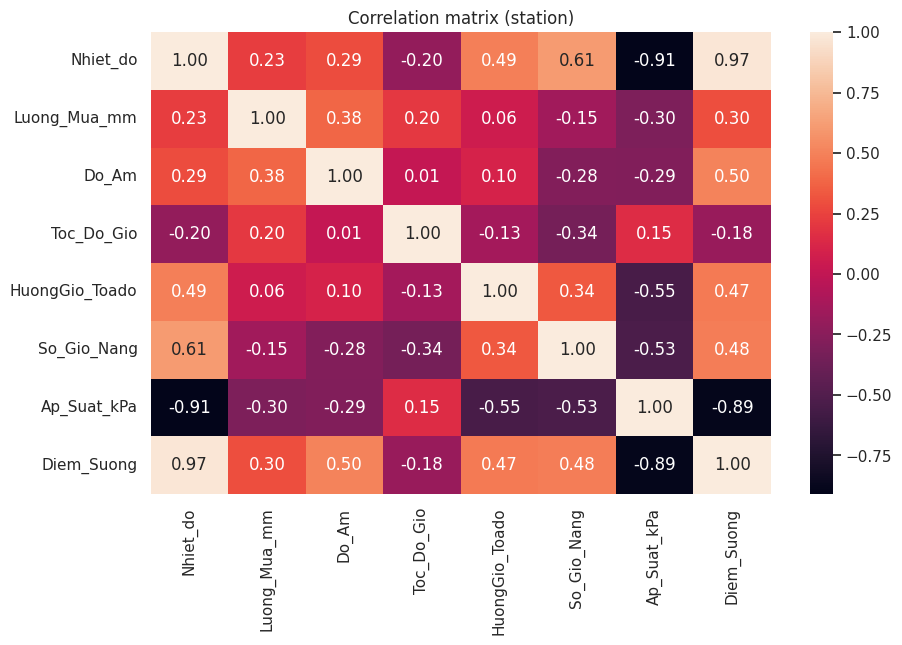

In [13]:
# Thiết lập kích thước của hình (figure) để đảm bảo hiển thị tốt hơn
plt.figure(figsize=(10,6))
sns.heatmap(df_station[features].corr(), annot=True, fmt='.2f') # Tạo ma trận tương quan bằng heatmap
# Đặt tiêu đề cho biểu đồ
plt.title('Correlation matrix (station)')
# Hiển thị biểu đồ
plt.show()

***Phân Tích Thành Phần Mùa Vụ***

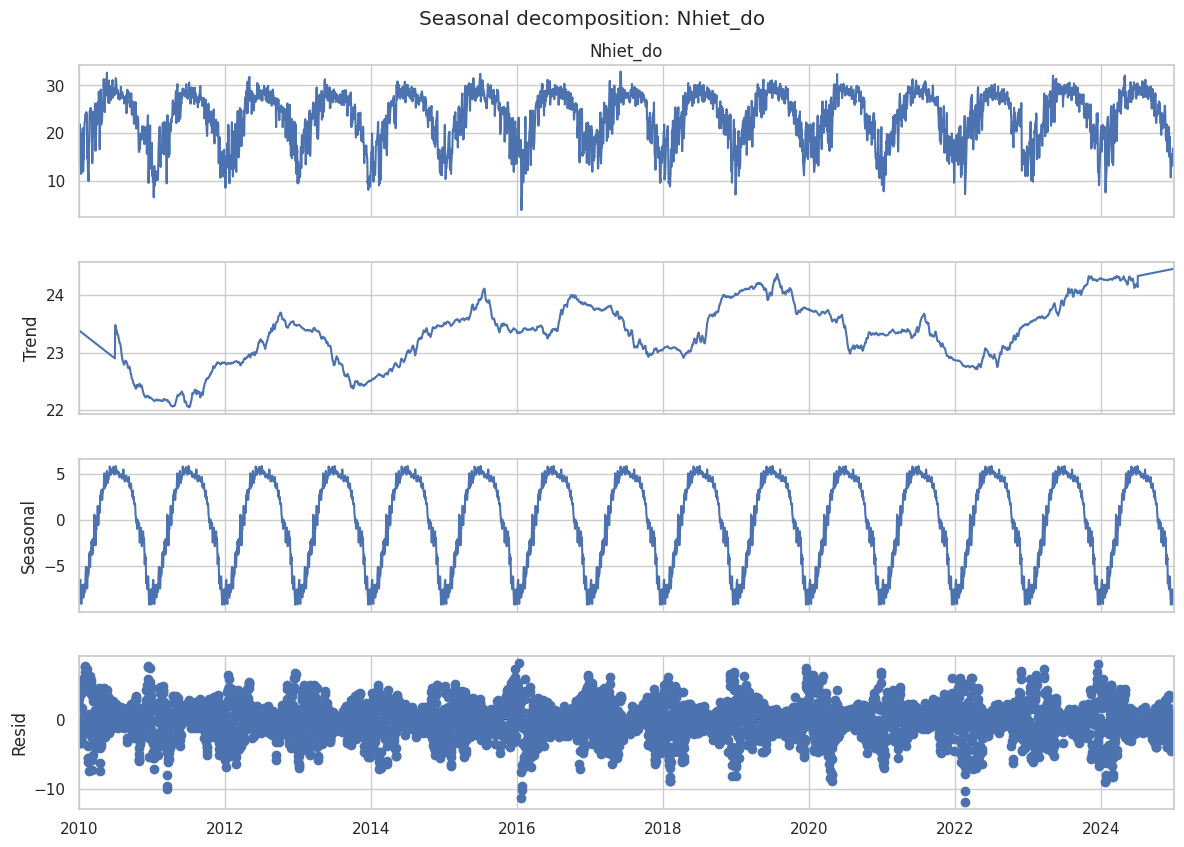

In [14]:
# Xác định biến mục tiêu (target) là cột đầu tiên trong danh sách features
target = features[0]
# Khối try-except để xử lý lỗi trong quá trình phân tích
try:
    # Chọn chuỗi thời gian (series) từ DataFrame df_station dựa trên target và loại bỏ các giá trị thiếu (NaN)
    series = df_station[target].dropna()
    # Xác định chu kỳ (period) cho phân tích mùa vụ.
    # Nếu độ dài của series lớn hơn 365, sử dụng chu kỳ là 365 (thường dùng cho dữ liệu hàng ngày). Ngược lại, không xác định chu kỳ (None) và seasonal_decompose sẽ cố gắng tự suy luận hoặc báo lỗi nếu không đủ dữ liệu.
    period = 365 if len(series) > 365 else None
    # Thực hiện phân rã mùa vụ (seasonal decomposition) của chuỗi thời gian.
    res = seasonal_decompose(series, model='additive', period=period, extrapolate_trend='freq')
    # Vẽ kết quả phân rã (chuỗi gốc, xu hướng, mùa vụ, phần dư)
    fig = res.plot()
    # Đặt kích thước cho hình vẽ (12x9 inches)
    fig.set_size_inches(12,9)
    # Đặt tiêu đề chính cho hình vẽ, bao gồm tên của biến mục tiêu
    plt.suptitle(f"Seasonal decomposition: {target}")
    # Hiển thị hình vẽ
    plt.show()
# Bắt các ngoại lệ (Exception) xảy ra trong khối try
except Exception as e:
    # In ra thông báo lỗi nếu quá trình phân rã mùa vụ thất bại
    print("Seasonal decomposition failed:", e)

# **Kỹ Thuật Trích Xuất và Tạo Đặc Trưng**

In [15]:
# Tạo lag và rolling features (dùng cho XGBoost nếu cần; CNN-LSTM dùng chuỗi thô sau scaling)
numeric_cols = features.copy()
MAX_LAG = 14

df_feat = df_station.copy()
# Bắt đầu tạo các features lag
for lag in range(1, MAX_LAG+1):
    for c in numeric_cols:
        # Tạo feature lag: dịch chuyển (shift) cột c đi 'lag' bước thời gian
        df_feat[f"{c}_lag{lag}"] = df_feat[c].shift(lag)

# Bắt đầu tạo các features rolling (trung bình trượt và độ lệch chuẩn trượt)
for w in [3,7]:
    for c in numeric_cols:
        # Tính Trung bình trượt (Moving Average) trong cửa sổ 'w' và dịch chuyển 1 bước (dùng giá trị quá khứ)
        df_feat[f"{c}_rollmean_{w}"] = df_feat[c].rolling(w).mean().shift(1)
        # Tính Độ lệch chuẩn trượt (Moving Standard Deviation) trong cửa sổ 'w' và dịch chuyển 1 bước
        df_feat[f"{c}_rollstd_{w}"] = df_feat[c].rolling(w).std().shift(1)

# Datetime features
if isinstance(df_feat.index, pd.DatetimeIndex):
    # Trích xuất các thành phần thời gian từ index
    df_feat['month'] = df_feat.index.month
    df_feat['day'] = df_feat.index.day
    df_feat['weekday'] = df_feat.index.weekday

# Xử lý dữ liệu khuyết (NaN)
# Drop NaN sinh ra do lag/rolling (các hàng đầu tiên của DataFrame)
df_feat = df_feat.dropna()
print('df_feat shape after feature eng:', df_feat.shape)
display(df_feat.head())

df_feat shape after feature eng: (5465, 158)


,ID,Nhiet_do,Luong_Mua_mm,Diem_Suong,Nam,HuongGio_Toado,Do_Am,Toc_Do_Gio,So_Gio_Nang,Ten_Tinh,...,HuongGio_Toado_rollstd_7,So_Gio_Nang_rollmean_7,So_Gio_Nang_rollstd_7,Ap_Suat_kPa_rollmean_7,Ap_Suat_kPa_rollstd_7,Diem_Suong_rollmean_7,Diem_Suong_rollstd_7,month,day,weekday
Date,,,,,,,,,,,,,,,,,,,,,
2010-01-15,1.0,14.84,1.43,12.79,2010.0,58.3,88.35,1.46,13.54,Hà Nội,...,38.978278,6.358571,2.345971,101.020000,0.511045,9.450000,4.663346,1,15,4
2010-01-16,1.0,14.87,3.10,11.25,2010.0,36.2,80.13,2.87,9.22,Hà Nội,...,38.933013,6.945714,3.482039,101.055714,0.515683,10.015714,4.813380,1,16,5
2010-01-17,1.0,15.56,0.00,12.61,2010.0,104.8,83.56,1.53,9.84,Hà Nội,...,12.565126,7.668571,3.329216,101.214286,0.458725,9.621429,4.536752,1,17,6
2010-01-18,1.0,15.91,0.00,13.28,2010.0,142.2,85.25,1.88,14.59,Hà Nội,...,24.179182,7.738571,3.375295,101.382857,0.213987,8.982857,3.510450,1,18,0
2010-01-19,1.0,17.47,0.00,15.10,2010.0,151.7,86.16,1.87,14.59,Hà Nội,...,39.338440,9.222857,3.815638,101.415714,0.147293,9.451429,3.869399,1,19,1


# **Tiền Xử Lý Dữ Liệu Huấn Luyện Mô Hình**

In [16]:
# Tham số
HORIZON = 5
WINDOW = 14
# Chuẩn hóa cho deep learning (chuỗi multivariate)
scaler = MinMaxScaler()
# Áp dụng chuẩn hóa min-max (0-1) trên các cột features của DataFrame
scaled = pd.DataFrame(scaler.fit_transform(df_station[features]), index=df_station.index, columns=features)
# Tạo sequence multivariate multi-step
def create_sequences_multi(arr, window, horizon):
    X, y = [], []
    n = arr.shape[0]
    # Lặp qua dữ liệu để tạo các cặp (chuỗi input X, chuỗi output y)
    for i in range(n - window - horizon + 1):
        # X là chuỗi window bước thời gian hiện tại
        X.append(arr[i:i+window, :])
        # y là chuỗi horizon bước thời gian sau X
        y.append(arr[i+window:i+window+horizon, :])
    # Trả về các mảng NumPy với kích thước (số_mẫu, độ_dài_chuỗi, số_features)
    return np.array(X), np.array(y)
# Thực hiện tạo các chuỗi
X_all, y_all = create_sequences_multi(scaled.values, WINDOW, HORIZON)
# In ra tổng số chuỗi đã tạo và kích thước của X (Input)
print('Total sequences:', X_all.shape) # Kích thước: (số_mẫu, WINDOW, số_features)
n_samples = X_all.shape[0]
# Chia tập dữ liệu: 70% Train, 15% Validation, 15% Test
train_n = int(n_samples * 0.7)
val_n = int(n_samples * 0.15)
# Lấy các phần tương ứng cho Train, Val, Test
X_train = X_all[:train_n]; y_train = y_all[:train_n]
X_val = X_all[train_n:train_n+val_n]; y_val = y_all[train_n:train_n+val_n]
X_test = X_all[train_n+val_n:]; y_test = y_all[train_n+val_n:]
# In ra kích thước của các tập dữ liệu sau khi chia
print('Shapes:', X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape)
# Các kích thước y_...: (số_mẫu, HORIZON, số_features)
# Chuyển đổi nhãn y từ 3D sang 2D để phù hợp với layer Dense cuối cùng: (số_mẫu, HORIZON * số_features)
y_train_flat = y_train.reshape(y_train.shape[0], -1)
y_val_flat = y_val.reshape(y_val.shape[0], -1)
y_test_flat = y_test.reshape(y_test.shape[0], -1)

Total sequences: (5461, 14, 8)
Shapes: (3822, 14, 8) (3822, 5, 8) (819, 14, 8) (819, 5, 8) (820, 14, 8) (820, 5, 8)


# **Hàm Hỗ Trợ: Chuẩn Hóa Nhãn Đầu Ra**

In [17]:
# Hàm này thực hiện phép biến đổi ngược cho một mảng (array) đã được scale (chuẩn hóa),
# chỉ áp dụng cho một cột (feature) cụ thể dựa trên thông tin từ đối tượng scaler (ví dụ: MinMaxScaler).
def inverse_scale_multi(scaled_array, scaler_obj, feature_idx):
    min_val = scaler_obj.min_[feature_idx]
    scale_val = scaler_obj.scale_[feature_idx]
    return scaled_array * scale_val + min_val

# Hàm này tính toán Sai số phần trăm tuyệt đối trung bình (Mean Absolute Percentage Error - MAPE). Nó đo lường độ chính xác của một phương pháp dự báo.
def mape(y_true, y_pred):
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Tạo mặt nạ để tránh chia cho 0. Chỉ tính toán ở những nơi giá trị thực (y_true) khác 0.
    mask = y_true != 0
    if not mask.any():
        # Trả về NaN nếu tất cả các giá trị thực đều bằng 0 (không thể tính MAPE).
        return np.nan
    # Công thức tính MAPE
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

# **Xây Dựng Mô Hình**

***ARIMA: huấn luyện trên từng feature theo chuỗi thời gian***

In [18]:
arima_results = {}  # Khởi tạo từ điển để lưu kết quả ARIMA (dự báo và mô hình)
print('Training ARIMA per feature...')
for feat in features:  # Lặp qua từng 'feature' (biến) trong danh sách
    # Chọn chuỗi thời gian cho 'feature' hiện tại, chuyển sang float và loại bỏ NaN
    series = df_station[feat].astype(float).dropna()
    if len(series) < 30:  # Kiểm tra xem chuỗi có đủ dài để huấn luyện ARIMA không
        print('Too short for ARIMA:', feat); arima_results[feat] = {'forecast': np.full(HORIZON, np.nan), 'model': None}; continue # Nếu quá ngắn, bỏ qua, lưu NaN vào kết quả và tiếp tục vòng lặp
    train_end = int(len(series) * 0.8) # Xác định điểm kết thúc cho tập huấn luyện (80% dữ liệu)
    train_series = series.iloc[:train_end] # Lấy tập huấn luyện
    try:
        model_a = ARIMA(train_series, order=(1,1,1)) # Khởi tạo mô hình ARIMA với thứ tự (p=1, d=1, q=1)
        res = model_a.fit() # Huấn luyện mô hình
        fc = res.forecast(steps=HORIZON) # Dự báo 'HORIZON' bước tiếp theo
        # Lưu trữ kết quả dự báo và mô hình đã huấn luyện
        arima_results[feat] = {'forecast': fc.values, 'model': res}
    except Exception as e:
        print('ARIMA failed for', feat, e) # Bắt lỗi nếu quá trình huấn luyện/dự báo ARIMA thất bại
        # Lưu NaN vào kết quả nếu quá trình thất bại
        arima_results[feat] = {'forecast': np.full(HORIZON, np.nan), 'model': None}
print('ARIMA done.')

Training ARIMA per feature...


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dat

ARIMA done.


***LSTM: mô hình LSTM -> Dense***

In [19]:
# Số lượng đặc trưng (features) trong dữ liệu, được lấy từ kích thước thứ 3 của mảng huấn luyện X_train
n_features = X_train.shape[2]
# Bằng Tầm nhìn dự đoán (HORIZON) nhân với số lượng đặc trưng để dự đoán nhiều bước thời gian và nhiều đặc trưng.
output_units = HORIZON * n_features
# 1. Khởi tạo mô hình mạng nơ-ron tuần tự (Sequential model)
lstm_model = Sequential()
# 2. Thêm lớp LSTM đầu tiên (128 đơn vị).
lstm_model.add(LSTM(128, return_sequences=True, input_shape=(WINDOW, n_features)))
# 3. Thêm lớp Dropout (tỷ lệ 20%) để giảm overfitting (quá khớp)
lstm_model.add(Dropout(0.2))
# 4. Thêm lớp LSTM thứ hai (64 đơn vị).
lstm_model.add(LSTM(64))# return_sequences mặc định là False, tức là đầu ra là một vector trạng thái cuối cùng.
# 5. Thêm lớp Fully Connected (Dense) với 64 đơn vị và hàm kích hoạt ReLU
lstm_model.add(Dense(64, activation='relu'))
# 6. Thêm lớp Dense đầu ra (số đơn vị = output_units) với hàm kích hoạt tuyến tính (linear).
lstm_model.add(Dense(output_units, activation='linear'))# Hàm linear được dùng cho các bài toán dự đoán giá trị liên tục (hồi quy).
# 7. Biên dịch mô hình:
lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
# 8. In ra bản tóm tắt kiến trúc mô hình (số lớp, hình dạng đầu ra, số tham số)
lstm_model.summary()
# 9. Khởi tạo Early Stopping (Dừng sớm)
es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# 10. Huấn luyện mô hình:
history_lstm = lstm_model.fit(X_train, y_train_flat, validation_data=(X_val, y_val_flat), epochs=60, batch_size=16, callbacks=[es], verbose=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 14, 128)        │        70,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │         2,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 126,312 (493.41 KB)

 Trainable params: 126,312 (493.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60
239/239 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - loss: 0.0616 - mae: 0.1699 - val_loss: 0.0166 - val_mae: 0.0921
Epoch 2/60
239/239 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.0180 - mae: 0.0968 - val_loss: 0.0165 - val_mae: 0.0917
Epoch 3/60
239/239 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.0175 - mae: 0.0953 - val_loss: 0.0165 - val_mae: 0.0915
Epoch 4/60
239/239 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0171 - mae: 0.0940 - val_loss: 0.0163 - val_mae: 0.0907
Epoch 5/60
239/239 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0166 - mae: 0.0923 - val_loss: 0.0160 - val_mae: 0.0894
Epoch 6/60
239/239 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - loss: 0.0162 - mae: 0.0906 - val_loss: 0.0157 - val_mae: 0.0881
Epoch 7/60
239/239 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - loss: 0.0160 - mae: 0.0898 - val_loss: 0.0155 - val_mae: 0.0873
Epoch 8/60
239/239 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.0158 - mae: 0.0889 - val_loss: 0.0154 - val_mae: 0.0870
Epoch 9/60
239/239 ━━━━━━━━━━━━━━━━━━━━ 6s 27m

# **Dự Báo Và Tổng Hợp Dữ Liệu**

In [20]:
# Thực hiện dự đoán trên tập dữ liệu kiểm tra X_test
lstm_pred_flat = lstm_model.predict(X_test)
# Định hình lại kết quả dự đoán phẳng thành (số mẫu, HORIZON, số tính năng)
lstm_pred = lstm_pred_flat.reshape(lstm_pred_flat.shape[0], HORIZON, n_features)
# Chuẩn bị từ kết quả scaled -> inverse scale
results = {}
# Lặp qua từng tính năng (đầu ra) để xử lý riêng
for i, feat in enumerate(features):
    # Lấy giá trị thực (đã được scaled) cho tính năng hiện tại
    true_scaled = y_test[:,:,i]
    # Lấy giá trị dự đoán (đã được scaled) từ LSTM cho tính năng hiện tại
    lstm_scaled = lstm_pred[:,:,i]
    # Thực hiện inverse scale (khôi phục về giá trị gốc) cho giá trị thực
    true_inv = inverse_scale_multi(true_scaled, scaler, i)
    # Thực hiện inverse scale (khôi phục về giá trị gốc) cho giá trị dự đoán LSTM
    lstm_inv = inverse_scale_multi(lstm_scaled, scaler, i)
    # Xử lý kết quả từ mô hình ARIMA (nếu có)
    if feat in arima_results:
        # Lặp lại dự báo ARIMA để khớp với số lượng mẫu kiểm tra
        arima_inv = np.tile(arima_results[feat]['forecast'], (true_inv.shape[0], 1))
    else:
        # Nếu không có kết quả ARIMA, điền giá trị NaN
        arima_inv = np.full(true_inv.shape, np.nan)
    # Lưu trữ kết quả (giá trị thực, dự đoán LSTM, dự đoán ARIMA) vào từ điển results
    results[feat] = {'true': true_inv, 'lstm': lstm_inv, 'arima': arima_inv}

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step


# **Đánh Giá Hiệu Suất Mô Hình**

***MAE, RMSE, MAPE***

In [21]:
eval_rows = []
# Bắt đầu vòng lặp qua từng đặc trưng/biến số (features)
for feat in features:
    # Lấy ra mảng 1 chiều (flatten) của giá trị thực ('true')
    true = results[feat]['true'].flatten()
    # Lấy ra mảng 1 chiều của giá trị dự đoán từ mô hình LSTM
    pred_lstm = results[feat]['lstm'].flatten()
    # Lấy ra mảng 1 chiều của giá trị dự đoán từ mô hình ARIMA
    pred_arima = results[feat]['arima'].flatten()
    # Định nghĩa hàm tính toán các metrics (MAE, RMSE, MAPE) một cách an toàn
    def safe_metrics(y_true, y_pred):
        # Kiểm tra nếu mảng dự đoán rỗng hoặc toàn là NaN, trả về NaN cho tất cả metrics
        if len(y_pred) == 0 or np.all(np.isnan(y_pred)):
            return {'MAE': np.nan, 'RMSE': np.nan, 'MAPE': np.nan}
        # Đảm bảo mảng thực và mảng dự đoán có cùng kích thước
        y_true, y_pred = y_true[:len(y_pred)], y_pred[:len(y_true)]
        return {
            # Tính sai số tuyệt đối trung bình
            'MAE': mean_absolute_error(y_true, y_pred),
            # Tính căn bậc hai của sai số bình phương trung bình
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            # Tính sai số phần trăm tuyệt đối trung bình
            'MAPE': mape(y_true, y_pred)}
    # Thêm một hàng mới vào danh sách đánh giá
    eval_rows.append({
        'Biến': feat,
        # Thêm các metrics của LSTM vào hàng, tiền tố là k_LSTM
        **{f'{k}_LSTM': v for k, v in safe_metrics(true, pred_lstm).items()},
        # Thêm các metrics của ARIMA vào hàng, tiền tố là k_ARIMA
        **{f'{k}_ARIMA': v for k, v in safe_metrics(true, pred_arima).items()}})
# Tạo DataFrame từ danh sách các hàng đánh giá
eval_df = pd.DataFrame(eval_rows)
print('Đánh giá:')
# Hiển thị DataFrame, làm tròn kết quả đến 3 chữ số thập phân
display(eval_df.round(3))

Đánh giá:


,Biến,MAE_LSTM,RMSE_LSTM,MAPE_LSTM,MAE_ARIMA,RMSE_ARIMA,MAPE_ARIMA
0,Nhiet_do,0.002,0.003,1.943,15.016,15.016,1.357352e+04
1,Luong_Mua_mm,0.000,0.001,3375.380,1.035,1.041,1.700028e+07
2,Do_Am,0.002,0.003,0.208,84.765,84.765,7.078494e+03
3,Toc_Do_Gio,0.006,0.008,11.463,2.515,2.517,4.566559e+03
4,HuongGio_Toado,0.000,0.001,1864.521,70.545,70.631,3.008903e+08
5,So_Gio_Nang,0.005,0.006,11.445,8.176,8.209,1.792528e+04
6,Ap_Suat_kPa,0.015,0.019,0.069,122.435,122.435,5.806840e+02
7,Diem_Suong,0.003,0.004,89.388,12.133,12.133,2.607086e+05


**Đánh Giá Mô Hình Tốt Nhất**

In [22]:
# Khởi tạo list lưu mô hình tốt nhất theo MAE, RMSE, MAPE
best_mae, best_rmse, best_mape = [], [], []
# Hàm chọn mô hình tốt nhất theo một metric
def get_best_model(row, metric_prefix):
    metrics = {
        'LSTM': row[f'{metric_prefix}_LSTM'],
        'ARIMA': row[f'{metric_prefix}_ARIMA'],}
    # Loại bỏ giá trị NaN
    valid = [(model, val) for model, val in metrics.items() if not pd.isna(val)]
    if not valid:
        return "No valid model"
    return min(valid, key=lambda x: x[1])[0]   # Model có giá trị nhỏ nhất
# Duyệt từng biến trong eval_df
for _, row in eval_df.iterrows():
    var = row['Biến']
    best_mae.append((var, get_best_model(row, 'MAE')))
    best_rmse.append((var, get_best_model(row, 'RMSE')))
    best_mape.append((var, get_best_model(row, 'MAPE')))
# Chuyển về DataFrame
df_mae = pd.DataFrame(best_mae, columns=['Biến', 'Mô hình tốt nhất (MAE)'])
df_rmse = pd.DataFrame(best_rmse, columns=['Biến', 'Mô hình tốt nhất (RMSE)'])
df_mape = pd.DataFrame(best_mape, columns=['Biến', 'Mô hình tốt nhất (MAPE)'])
# Hiển thị kết quả
print("\n===== BẢNG KẾT QUẢ THEO MAE =====")
display(df_mae)
print("\n===== BẢNG KẾT QUẢ THEO RMSE =====")
display(df_rmse)
print("\n===== BẢNG KẾT QUẢ THEO MAPE =====")
display(df_mape)


===== BẢNG KẾT QUẢ THEO MAE =====


,Biến,Mô hình tốt nhất (MAE)
0,Nhiet_do,LSTM
1,Luong_Mua_mm,LSTM
2,Do_Am,LSTM
3,Toc_Do_Gio,LSTM
4,HuongGio_Toado,LSTM
5,So_Gio_Nang,LSTM
6,Ap_Suat_kPa,LSTM
7,Diem_Suong,LSTM



===== BẢNG KẾT QUẢ THEO RMSE =====


,Biến,Mô hình tốt nhất (RMSE)
0,Nhiet_do,LSTM
1,Luong_Mua_mm,LSTM
2,Do_Am,LSTM
3,Toc_Do_Gio,LSTM
4,HuongGio_Toado,LSTM
5,So_Gio_Nang,LSTM
6,Ap_Suat_kPa,LSTM
7,Diem_Suong,LSTM



===== BẢNG KẾT QUẢ THEO MAPE =====


,Biến,Mô hình tốt nhất (MAPE)
0,Nhiet_do,LSTM
1,Luong_Mua_mm,LSTM
2,Do_Am,LSTM
3,Toc_Do_Gio,LSTM
4,HuongGio_Toado,LSTM
5,So_Gio_Nang,LSTM
6,Ap_Suat_kPa,LSTM
7,Diem_Suong,LSTM


# **Trực Quan Dữ Liệu và Kết Quả Dự Báo**

***Biểu Đồ Trực Quan Hóa***

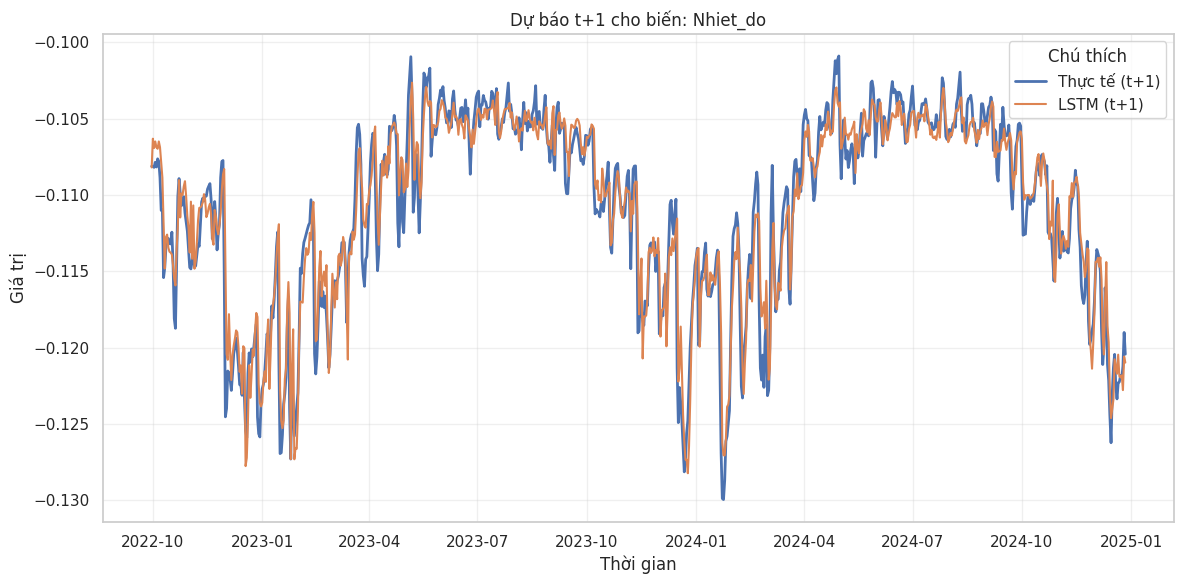

In [23]:
# --- Thiết lập ---
feat = features[0]      # chọn biến đầu tiên để vẽ
plt.figure(figsize=(12, 6))
# --- Tạo chỉ số thời gian cho tập test ---
# test_index mặc định để dự phòng
test_index = pd.date_range(start=df_station.index[0], periods=X_all.shape[0])
# Tính vị trí offset của dữ liệu test
idx_offset = WINDOW + train_n + val_n
end_idx = idx_offset + X_test.shape[0]
# Nếu đủ dữ liệu trong df_station thì dùng index thật
if end_idx <= len(df_station):
    test_index = df_station.index[idx_offset:end_idx]
else:
    # Nếu không đủ, tạo lại chuỗi ngày cho X_test
    test_index = pd.date_range(start=df_station.index[-X_test.shape[0]], periods=X_test.shape[0])
# --- Vẽ biểu đồ ---
plt.plot(test_index, results[feat]['true'][:, 0], label='Thực tế (t+1)', linewidth=2)
plt.plot(test_index, results[feat]['lstm'][:, 0], label='LSTM (t+1)')
# Kiểm tra nếu có dự báo ensemble trước khi vẽ
if 'ens' in results[feat]:
    plt.plot(test_index, results[feat]['ens'][:, 0],  label='Ensemble (t+1)')
else:
    print(f"Warning: Ensemble predictions (key 'ens') not found for feature '{feat}' in results dictionary. Skipping ensemble plot.")
# --- Thêm tiêu đề và bảng chú thích ---
plt.title(f'Dự báo t+1 cho biến: {feat}')
plt.xlabel('Thời gian')
plt.ylabel('Giá trị')
plt.legend(title='Chú thích', loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

***ARIMA (Lấy Anchor Từ Cuối Train)***

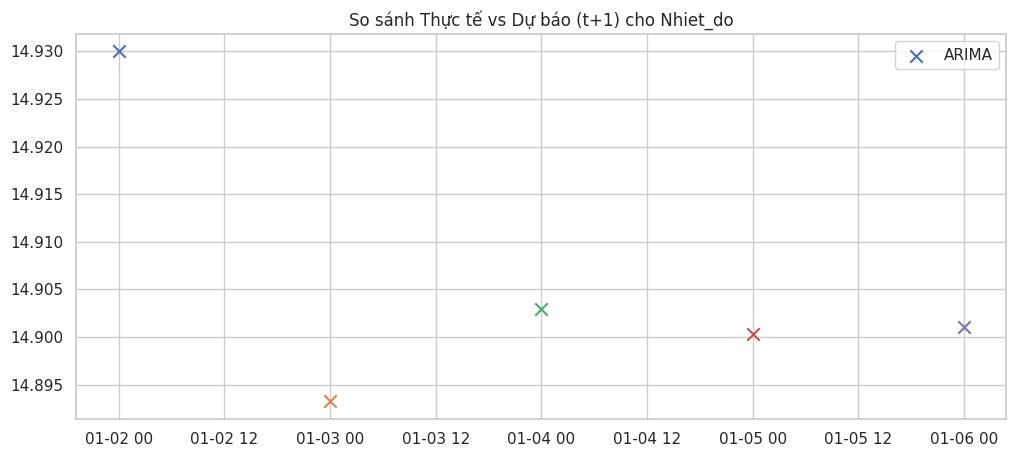

In [24]:
# Xác định ngày neo (anchor date) làm mốc phân chia dữ liệu huấn luyện/kiểm thử (80% dữ liệu)
anchor_date = df_station.index[int(len(df_station)*0.8)]
# Kiểm tra xem kết quả ARIMA có tồn tại (không phải toàn bộ là NaN) không
if not np.all(np.isnan(results[feat]['arima'])):
    # Lặp qua từng bước thời gian dự báo (horizon)
    for h in range(HORIZON):
        # Vẽ điểm dự báo ARIMA cho ngày t+1 (h+1 ngày sau anchor_date)
        # Sử dụng marker 'x' và kích thước s=80
        # Gán nhãn 'ARIMA' chỉ cho điểm đầu tiên (h=0) để tránh trùng lặp trong legend
        plt.scatter(anchor_date + pd.Timedelta(days=h+1), results[feat]['arima'][0, h], marker='x', s=80, label='ARIMA' if h==0 else '')
# Đặt tiêu đề cho biểu đồ
plt.title(f"So sánh Thực tế vs Dự báo (t+1) cho {feat}")
# Hiển thị chú giải (legend)
plt.legend()
# Hiển thị biểu đồ
plt.show()

# **Hàm Mất Mát**

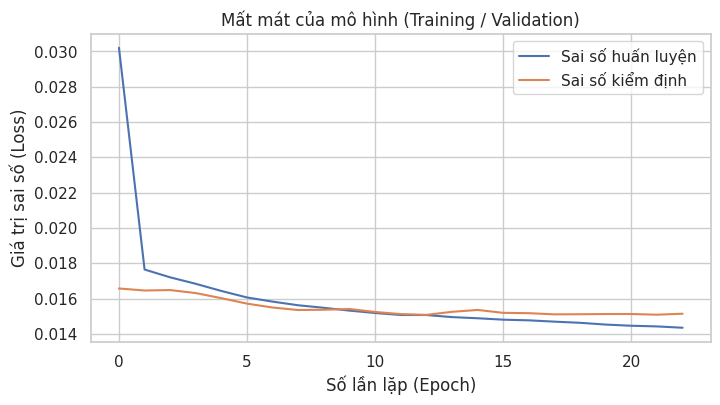

In [25]:
plt.figure(figsize=(8,4))  # Tạo figure mới với kích thước 8x4 inch
# Vẽ đường biểu diễn sai số trên tập huấn luyện và tập kiểm định
plt.plot(history_lstm.history['loss'], label='Sai số huấn luyện')      # Loss trên tập huấn luyện
plt.plot(history_lstm.history['val_loss'], label='Sai số kiểm định')   # Loss trên tập kiểm định
# Thiết lập tiêu đề và nhãn cho biểu đồ
plt.title('Mất mát của mô hình (Training / Validation)')  # Tiêu đề biểu đồ
plt.xlabel('Số lần lặp (Epoch)')                                 # Nhãn trục x
plt.ylabel('Giá trị sai số (Loss)')                              # Nhãn trục y
plt.legend()                                                      # Hiển thị chú thích
# Hiển thị biểu đồ
plt.show()

# **Xuất Kết Quả**

In [26]:
# Tạo thư mục đầu ra nếu chưa tồn tại
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)
# Lưu mô hình LSTM đã huấn luyện vào thư mục đầu ra
MODEL_PATH = os.path.join(OUTPUT_DIR, "lstm_model.h5")
lstm_model.save(MODEL_PATH)
# Lưu đối tượng scaler (dùng để chuẩn hóa dữ liệu) vào thư mục đầu ra
SCALER_PATH = os.path.join(OUTPUT_DIR, "scaler.pkl")
import pickle
with open(SCALER_PATH, "wb") as f:
    pickle.dump(scaler, f)
print("Đã lưu:")
print(" - Model:", MODEL_PATH)
print(" - Scaler:", SCALER_PATH)

Đã lưu:
 - Model: output/lstm_model.h5
 - Scaler: output/scaler.pkl
